## 教程（官方文档）

MultiIndex

https://zhuanlan.zhihu.com/p/74461994?utm_psn=1766758982935412736

pandas.DataFrame

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html?highlight=pandas%20dataframe#pandas.DataFrame

pandas.DataFrame.to_excel

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_excel.html?highlight=to_excel#pandas.DataFrame.to_excel

pandas.ExcelWriter

https://pandas.pydata.org/docs/reference/api/pandas.ExcelWriter.html?highlight=excelwriter#pandas.ExcelWriter

pandas.read_excel

https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html?highlight=pandas%20read_excel#pandas.read_excel

get started

https://pandas.pydata.org/docs/getting_started/index.html#getting-started

## pd.set_option

In [ ]:
pd.set_option('display.max_rows',xxx) # 最大行数
pd.set_option('display.min_rows',xxx) # 最小显示行数
pd.set_option('display.max_columns',xxx) # 最大显示列数
pd.set_option ('display.max_colwidth',xxx) #最大列字符数
pd.set_option( 'display.precision',2) # 浮点型精度
pd.set_option('display.float_format','{:,}'.format) #逗号分隔数字
pd.set_option('display.float_format',  '{:,.2f}'.format) #设置浮点精度
pd.set_option('display.float_format', '{:.2f}%'.format) #百分号格式化
pd.set_option('plotting.backend', 'altair') # 更改后端绘图方式
pd.set_option('display.max_info_columns', 200) # info输出最大列数
pd.set_option('display.max_info_rows', 5) # info计数null时的阈值
pd.describe_option() #展示所有设置和描述
pd.reset_option('all') #重置所有设置选项

## 数据源-DataFrame

In [1]:
import pandas as pd

data_src = pd.DataFrame([{'step':1, 'frac':1, 'value':2.1}, {'step':1, 'frac':2, 'value':3.1}, 
                     {'step':2, 'frac':1, 'value':4.1}, {'step':2, 'frac':2, 'value':5.1}])
data_src

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


## 数据源-MultiIndex

In [93]:
import pandas as pd
import numpy as np

index = pd.MultiIndex.from_product([['bar', 'baz', 'foo', 'qux'], ['one', 'two']], names=['first', 'second'])
data_srcm = pd.DataFrame(np.random.randn(3,8), index=['A', 'B', 'c'], columns=index)
data_srcm

first        bar                 baz                 foo                 qux  \
second       one       two       one       two       one       two       one   
A       0.814078 -0.065172  0.167039 -1.184355  0.529385 -0.304737 -1.394530   
B       0.246924  2.480815  0.949478  0.660161 -0.005081 -1.346298  2.490770   
c       0.108536  0.330978  1.476564 -1.228788 -0.109563 -2.123509 -0.643686   

first             
second       two  
A       0.306217  
B       0.423205  
c      -1.246285

## 创建Series的3中方式

### 从列表创建

In [2]:
import pandas as pd

l = [1,2,3]
data = pd.Series(l)
data

0    1
1    2
2    3
dtype: int64

In [3]:
data[1]

2

### 从字典创建

In [6]:
d = {'a':1, 'b':2}
data = pd.Series(d)
data

a    1
b    2
dtype: int64

In [8]:
data['a']

1

### 从np.arrray创建

In [5]:
import numpy as np

a = np.arange(1,4)
data = pd.Series(a)
data

0    1
1    2
2    3
dtype: int32

## 创建DataFrame的4种方式

### 从列表创建

In [25]:
import pandas as pd

l = [{'step':1, 'frac':1, 'value':2.1}, {'step':1, 'frac':2, 'value':3.1}]
data = pd.DataFrame(l)
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1


### 从字典创建

#### 标准方式

要求字典的值是列表，且列表具有相同的长度

In [10]:
import pandas as pd

d = {'step':[1,1], 'frac':[1,2], 'value':[2.1, 3.1]}
data = pd.DataFrame(d)
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1


#### 字典的值只有一个元素

**报错**

In [11]:
import pandas as pd

d = {'step':1, 'frac':1, 'value':2.1}
data = pd.DataFrame(d)
data

ValueError: If using all scalar values, you must pass an index

**推荐---指定index=[0]**

In [12]:
import pandas as pd

d = {'step':1, 'frac':1, 'value':2.1}
data = pd.DataFrame(d, index=[0])
data

,step,frac,value
0,1,1,2.1


**指定index=[0,1,2]**

In [13]:
import pandas as pd

d = {'step':1, 'frac':1, 'value':2.1}
data = pd.DataFrame(d, index=[0,1,2])
data

,step,frac,value
0,1,1,2.1
1,1,1,2.1
2,1,1,2.1


**list(dict.items())**

In [14]:
import pandas as pd

d = {'step':1, 'frac':1, 'value':2.1}
data = pd.DataFrame(list(d.items()))
data

,0,1
0,step,1.0
1,frac,1.0
2,value,2.1


**from_dict**

In [16]:
import pandas as pd

d = {'step':1, 'frac':1, 'value':2.1}
data = pd.DataFrame.from_dict(d, orient='index')
data

,0
step,1.0
frac,1.0
value,2.1


### 从np.array创建

In [27]:
import pandas as pd
import numpy as np

a = np.random.rand(3,4)
data = pd.DataFrame(a, columns=['c1', 'c2', 'c3', 'c4'])
data

,c1,c2,c3,c4
0,0.677660,0.036628,0.032962,0.487348
1,0.857222,0.951511,0.665086,0.435552
2,0.437326,0.041790,0.298786,0.735759


### 从文件创建

pd.read_csv, pd.read_excel

## 创建MultiIndex的4种方式

### from_arrays

In [73]:
import pandas as pd
import numpy as np

a = [['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'],
    ['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']]

index = pd.MultiIndex.from_arrays(a, names=['first', 'second'])
data = pd.Series(np.random.randn(8), index=index)
data

first  second
bar    one      -0.563646
       two      -0.041778
baz    one      -1.053783
       two       2.557425
foo    one       0.675124
       two       1.184579
qux    one       0.152094
       two       0.709369
dtype: float64

### from_tuples

In [75]:
import pandas as pd
import numpy as np

a = [['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'],
    ['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']]

tuples = list(zip(*a))
print(tuples)
index = pd.MultiIndex.from_tuples(tuples, names=['first', 'second'])
data = pd.Series(np.random.randn(8), index=index)
data

[('bar', 'one'), ('bar', 'two'), ('baz', 'one'), ('baz', 'two'), ('foo', 'one'), ('foo', 'two'), ('qux', 'one'), ('qux', 'two')]


first  second
bar    one      -0.091599
       two      -0.094426
baz    one      -1.567050
       two       0.323767
foo    one       0.850027
       two      -0.116581
qux    one      -0.016025
       two      -1.168548
dtype: float64

### from_product

In [76]:
import pandas as pd
import numpy as np

a = [['bar', 'baz', 'foo', 'qux'], ['one', 'two']]

index = pd.MultiIndex.from_product(a, names=['first', 'second'])
data = pd.Series(np.random.randn(8), index=index)
data

first  second
bar    one      -1.276027
       two      -1.381990
baz    one       0.658226
       two       0.066511
foo    one       1.084939
       two       0.811622
qux    one      -1.047622
       two       1.090687
dtype: float64

### from_frame

In [77]:
import pandas as pd
import numpy as np

a = pd.DataFrame([['bar', 'one'], ['bar','two'], ['baz', 'one'], ['baz', 'two'], ['foo', 'one'], ['foo', 'two'], ['qux', 'one'], ['qux', 'two']], columns=['first', 'second'])
index = pd.MultiIndex.from_frame(a)
data = pd.Series(np.random.randn(8), index=index)
data

first  second
bar    one      -0.284500
       two      -1.348532
baz    one       0.228216
       two       2.841154
foo    one       1.942807
       two       2.991932
qux    one       1.870179
       two       0.299360
dtype: float64

## 功能汇总

### 将二维数组存储到一列DataFrame

In [1]:
import pandas as pd
import numpy as np

data = pd.DataFrame(np.random.rand(3,4))
data

,0,1,2,3
0,0.697615,0.754022,0.948215,0.454080
1,0.867888,0.929000,0.576797,0.900337
2,0.691313,0.189820,0.955577,0.633068


In [2]:
new = np.random.rand(3,2)
new

array([[0.90985858, 0.39446774],
       [0.05349984, 0.1563643 ],
       [0.5601689 , 0.30174289]])

In [3]:
data['new'] = new
data

ValueError: Wrong number of items passed 2, placement implies 1

In [4]:
data['new'] = pd.Series(dtype=object)
data['new'] = new
data

,0,1,2,3,new
0,0.697615,0.754022,0.948215,0.454080,0.909859
1,0.867888,0.929000,0.576797,0.900337,0.053500
2,0.691313,0.189820,0.955577,0.633068,0.560169


**发现只存进去了一列数据，这个时候需要使用tuple**

In [5]:
new1 = list(map(tuple, new))
new1

[(0.909858580423731, 0.3944677410089581),
 (0.05349983571991124, 0.15636429975028243),
 (0.5601689019906898, 0.30174288672089256)]

In [6]:
data['new1'] = new1
data

,0,1,2,3,new,new1
0,0.697615,0.754022,0.948215,0.454080,0.909859,"(0.909858580423731, 0.3944677410089581)"
1,0.867888,0.929000,0.576797,0.900337,0.053500,"(0.05349983571991124, 0.15636429975028243)"
2,0.691313,0.189820,0.955577,0.633068,0.560169,"(0.5601689019906898, 0.30174288672089256)"


## 数据检查

### head

In [29]:
data_src.head(3)

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1


### tail

In [31]:
data_src.tail(3)

,step,frac,value
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


### info()

In [33]:
data_src.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   step    4 non-null      int64  
 1   frac    4 non-null      int64  
 2   value   4 non-null      float64
dtypes: float64(1), int64(2)
memory usage: 224.0 bytes


### dtype

In [38]:
data_src.dtypes

step       int64
frac       int64
value    float64
dtype: object

### describe()

In [39]:
data_src.describe()

,step,frac,value
count,4.00000,4.00000,4.000000
mean,1.50000,1.50000,3.600000
std,0.57735,0.57735,1.290994
min,1.00000,1.00000,2.100000
25%,1.00000,1.00000,2.850000
50%,1.50000,1.50000,3.600000
75%,2.00000,2.00000,4.350000
max,2.00000,2.00000,5.100000


### mean(), median(), min(), max(), skew()

In [90]:
data_src.mean()

step     1.5
frac     1.5
value    3.6
dtype: float64

In [91]:
data_src.median()

step     1.5
frac     1.5
value    3.6
dtype: float64

In [92]:
data_src.min()

step     1.0
frac     1.0
value    2.1
dtype: float64

In [93]:
data_src.max()

step     2.0
frac     2.0
value    5.1
dtype: float64

In [94]:
data_src.skew()

step     0.0
frac     0.0
value    0.0
dtype: float64

## 条件判断

通常会返回一个row number大小的Series， 元素是bool

In [41]:
data_src['step'].shape

(4,)

In [42]:
data_src['step']>1

0    False
1    False
2     True
3     True
Name: step, dtype: bool

In [45]:
data_src[data_src['step']>1]

,step,frac,value
2,2,1,4.1
3,2,2,5.1


In [46]:
data_src[data_src['step']>1]['step']

2    2
3    2
Name: step, dtype: int64

**注意多个条件使用()，否则报错**

In [48]:
data_src[(data_src['step']>1) & (data_src['frac']>1)]

,step,frac,value
3,2,2,5.1


**isin**

In [50]:
data_src[data_src['step'].isin([1])]

,step,frac,value
0,1,1,2.1
1,1,2,3.1


**notna**

In [51]:
data_src[data_src['step'].notna()]

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


## 缺失值

### 缺失值类型

None (python built-in)

NA (Not Availabel in pandas)

NaN (for number)

### 缺失值处理

https://blog.csdn.net/qq_18351157/article/details/104993254

## 提取数据

### 提取行数据

**只能通过loc提取**

In [62]:
data_src.loc[2]

step     2.0
frac     1.0
value    4.1
Name: 2, dtype: float64

### 提取列数据

**可以直接提取**

**也可以通过loc提取，但是行的：不能省略**

In [72]:
data_src['step']

0    1
1    1
2    2
3    2
Name: step, dtype: int64

In [67]:
data_src.loc[:,'step']

0    1
1    1
2    2
3    2
Name: step, dtype: int64

### 提取某个值

**可以先提取某列，然后再对行进行索引**

**也可以使用loc直接进行提取**

#### loc

In [76]:
data_src['value'][2]

4.1

In [77]:
data_src.loc[2, 'value']

4.1

#### at

In [4]:
data_src.at[2, 'value']

4.1

### 遍历

#### iteritems

In [13]:
for i in data_src.iteritems():
    print(i)
    print('-'*20)

print('-'*40)
    
for k,v in data_src.iteritems():
    print(k,v)
    print('-'*20)
    
print('-'*40)

for k,v in data_src.iteritems():
    print(k)
    print('-'*20)

print('-'*40)

for k,v in data_src.iteritems():
    print(v)
    print('-'*20)

('step', 0    1
1    1
2    2
3    2
Name: step, dtype: int64)
--------------------
('frac', 0    1
1    2
2    1
3    2
Name: frac, dtype: int64)
--------------------
('value', 0    2.1
1    3.1
2    4.1
3    5.1
Name: value, dtype: float64)
--------------------
----------------------------------------
step 0    1
1    1
2    2
3    2
Name: step, dtype: int64
--------------------
frac 0    1
1    2
2    1
3    2
Name: frac, dtype: int64
--------------------
value 0    2.1
1    3.1
2    4.1
3    5.1
Name: value, dtype: float64
--------------------
----------------------------------------
step
--------------------
frac
--------------------
value
--------------------
----------------------------------------
0    1
1    1
2    2
3    2
Name: step, dtype: int64
--------------------
0    1
1    2
2    1
3    2
Name: frac, dtype: int64
--------------------
0    2.1
1    3.1
2    4.1
3    5.1
Name: value, dtype: float64
--------------------


#### iterrows

In [15]:
for i in data_src.iterrows():
    print(i)
    print('-'*20)

print('-'*40)
    
for k,v in data_src.iterrows():
    print(k,v)
    print('-'*20)
    
print('-'*40)

for k,v in data_src.iterrows():
    print(k)
    print('-'*20)

print('-'*40)

for k,v in data_src.iterrows():
    print(v)
    print('-'*20)

(0, step     1.0
frac     1.0
value    2.1
Name: 0, dtype: float64)
--------------------
(1, step     1.0
frac     2.0
value    3.1
Name: 1, dtype: float64)
--------------------
(2, step     2.0
frac     1.0
value    4.1
Name: 2, dtype: float64)
--------------------
(3, step     2.0
frac     2.0
value    5.1
Name: 3, dtype: float64)
--------------------
----------------------------------------
0 step     1.0
frac     1.0
value    2.1
Name: 0, dtype: float64
--------------------
1 step     1.0
frac     2.0
value    3.1
Name: 1, dtype: float64
--------------------
2 step     2.0
frac     1.0
value    4.1
Name: 2, dtype: float64
--------------------
3 step     2.0
frac     2.0
value    5.1
Name: 3, dtype: float64
--------------------
----------------------------------------
0
--------------------
1
--------------------
2
--------------------
3
--------------------
----------------------------------------
step     1.0
frac     1.0
value    2.1
Name: 0, dtype: float64
--------------------
s

#### itertuples

In [17]:
for i in data_src.itertuples():
    print(i)
    print('-'*20)

print('-'*40)

Pandas(Index=0, step=1, frac=1, value=2.1)
--------------------
Pandas(Index=1, step=1, frac=2, value=3.1)
--------------------
Pandas(Index=2, step=2, frac=1, value=4.1)
--------------------
Pandas(Index=3, step=2, frac=2, value=5.1)
--------------------
----------------------------------------


### 笔记

**只要涉及到行的，都需要使用loc进行提取**

## 可视化

### 自带plot属性

<AxesSubplot:>

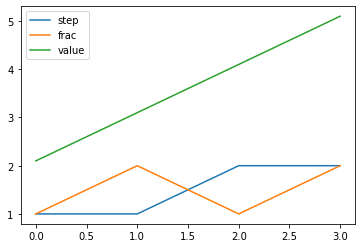

In [78]:
data_src.plot()

<AxesSubplot:>

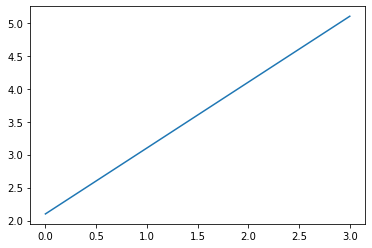

In [79]:
data_src['value'].plot()

### plot.box()

<AxesSubplot:>

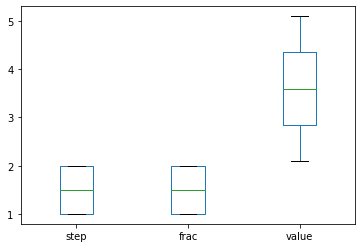

In [85]:
data_src.plot.box()

<AxesSubplot:>

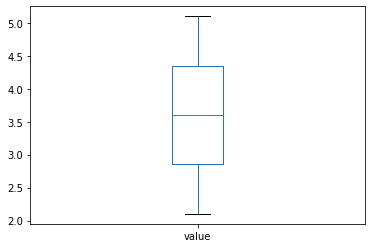

In [86]:
data_src['value'].plot.box()

### plot.scatter(x,y)

**DataFrame.plot.scatter()需要指定x，y，都不可以缺省**

<AxesSubplot:xlabel='frac', ylabel='value'>

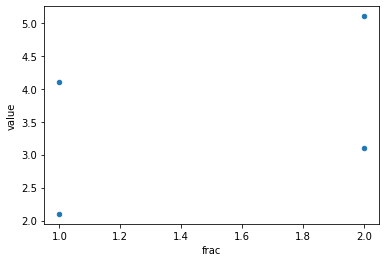

In [89]:
data_src.plot.scatter('frac', 'value')

## 数据分析

### agg

**使用agg是将min，max等这些值作为行标签**

In [95]:
data_src.agg(['mean', 'max'])

,step,frac,value
mean,1.5,1.5,3.6
max,2.0,2.0,5.1


**注意这里的step.max为NaN**

In [96]:
data_src.agg({'step':['mean', 'skew'], 'frac':['mean', 'max']})

,step,frac
max,NaN,2.0
mean,1.5,1.5
skew,0.0,NaN


### groupby

**使用groupby是将某个column作为行标签**

In [109]:
print(type(data_src.groupby('frac')))

pandas.core.groupby.generic.DataFrameGroupBy


In [110]:
data_src.groupby('frac').describe()

step                                           value                 \
     count mean       std  min   25%  50%   75%  max count mean       std   
frac                                                                        
1      2.0  1.5  0.707107  1.0  1.25  1.5  1.75  2.0   2.0  3.1  1.414214   
2      2.0  1.5  0.707107  1.0  1.25  1.5  1.75  2.0   2.0  4.1  1.414214   

                               
      min  25%  50%  75%  max  
frac                           
1     2.1  2.6  3.1  3.6  4.1  
2     3.1  3.6  4.1  4.6  5.1

In [111]:
data_src.groupby('frac').mean()

,step,value
frac,,
1,1.5,3.1
2,1.5,4.1


**注意这里出现了两个列标签，第一个是分组用的frac，第二个是step**

In [113]:
data_src.groupby('frac')['step'].mean()

frac
1    1.5
2    1.5
Name: step, dtype: float64

In [114]:
data_src.groupby(['frac', 'step']).mean()

value
frac step       
1    1       2.1
     2       4.1
2    1       3.1
     2       5.1

### value_counts()

In [117]:
data_src.value_counts()

step  frac  value
2     2     5.1      1
      1     4.1      1
1     2     3.1      1
      1     2.1      1
dtype: int64

In [123]:
data_src['step'].value_counts()

2    2
1    2
Name: step, dtype: int64

**对于groupby使用count或size代替value_counts(size包含NaN)**

In [121]:
data_src.groupby('step').count()

,frac,value
step,,
1,2,2
2,2,2


In [122]:
data_src.groupby('step')['step'].count()

step
1    2
2    2
Name: step, dtype: int64

In [124]:
data_src.groupby('step')['step'].size()

step
1    2
2    2
Name: step, dtype: int64

## 数据重组（reshape）

### reset_index

**删除level，将旧的索引添加为列**

In [15]:
data_src.groupby('frac').mean()

,step,value
frac,,
1,1.5,3.1
2,1.5,4.1


In [16]:
data_src.groupby('frac').mean().reset_index()

,frac,step,value
0,1,1.5,3.1
1,2,1.5,4.1


### sort_index

**根据index或者column的值进行排序**

In [132]:
data_src.sort_index(axis=0, ascending=True, inplace=False, na_position='last')

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


In [133]:
data_src.sort_index(axis=1, ascending=True, inplace=False, na_position='last')

,frac,step,value
0,1,1,2.1
1,2,1,3.1
2,1,2,4.1
3,2,2,5.1


### sort_values

**按照某一行的值或者某一列的值进行排序**

**第一个参数是by，不能缺省，如果axis=0，by=column，如果axis=1， by=index**

In [137]:
data_src.sort_values(by='frac', axis=0, ascending=True, inplace=False, kind='quicksort', na_position='last')

,step,frac,value
0,1,1,2.1
2,2,1,4.1
1,1,2,3.1
3,2,2,5.1


In [139]:
data_src.sort_values(by=2, axis=1, ascending=True, inplace=False, kind='quicksort', na_position='last')

,frac,step,value
0,1,1,2.1
1,2,1,3.1
2,1,2,4.1
3,2,2,5.1


In [140]:
data_src.sort_values(by=['frac', 'step'], axis=0, ascending=True, inplace=False, kind='quicksort', na_position='last')

,step,frac,value
0,1,1,2.1
2,2,1,4.1
1,1,2,3.1
3,2,2,5.1


### pivot

**有三个参数，index，columns，values，其中columns不能缺省**

In [2]:
data_src.pivot(columns='frac')

step      value     
frac    1    2     1    2
0     1.0  NaN   2.1  NaN
1     NaN  1.0   NaN  3.1
2     2.0  NaN   4.1  NaN
3     NaN  2.0   NaN  5.1

In [7]:
data_src.pivot(index='step', columns='frac', values='value')

frac,1,2
step,,
1,2.1,3.1
2,4.1,5.1


### pivot_table

**pivot_table相比pivot添加了默认的aggfunc=‘mean’**

In [8]:
data_src.pivot_table(columns='frac')

frac,1,2
step,1.5,1.5
value,3.1,4.1


In [12]:
data_src.pivot_table(index='step', columns='frac', values='value', aggfunc='max')

frac,1,2
step,,
1,2.1,3.1
2,4.1,5.1


### melt

In [18]:
data_src.melt(id_vars='value')

c:\software\python\lib\site-packages\ipykernel_launcher.py:1: FutureWarning: This dataframe has a column name that matches the 'value_name' column name of the resultiing Dataframe. In the future this will raise an error, please set the 'value_name' parameter of DataFrame.melt to a unique name.
  """Entry point for launching an IPython kernel.


,value,variable,value
0,1,step,1
1,1,step,1
2,2,step,2
3,2,step,2
4,1,frac,1
5,2,frac,2
6,1,frac,1
7,2,frac,2


## 拼接数据

### concat

#### outer（默认）

In [34]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=0, join='outer')
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


In [35]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=1)
data

,step,frac,value,step,frac,value
0,1,1,2.1,1,1,2.1
1,1,2,3.1,1,2,3.1
2,2,1,4.1,2,1,4.1
3,2,2,5.1,2,2,5.1


#### inner

In [36]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=0, join='inner')
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


In [37]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=1, join='inner')
data

,step,frac,value,step,frac,value
0,1,1,2.1,1,1,2.1
1,1,2,3.1,1,2,3.1
2,2,1,4.1,2,1,4.1
3,2,2,5.1,2,2,5.1


#### 避免columns重复

**使用ignore_index避免列名重复**

In [24]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=1, ignore_index=True)
data

,0,1,2,3,4,5
0,1,1,2.1,1,1,2.1
1,1,2,3.1,1,2,3.1
2,2,1,4.1,2,1,4.1
3,2,2,5.1,2,2,5.1


**使用verify_integrity避免列名重复**

In [25]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=1, verify_integrity=True)
data

ValueError: Indexes have overlapping values: Index(['step', 'frac', 'value'], dtype='object')

**使用has_duplicates避免列名重复**

In [28]:
data1 = data_src
data2 = data_src

data = pd.concat([data1, data2], axis=1)
data.columns.has_duplicates

True

### merge

In [44]:
from copy import deepcopy
data1 = data_src
data2 = deepcopy(data_src)
data2['i'] = [1,2,3,4]

data = pd.merge(data1, data2, how='left')
data

,step,frac,value,i
0,1,1,2.1,1
1,1,2,3.1,2
2,2,1,4.1,3
3,2,2,5.1,4


### join

**完全按照两个dataframe的索引进行拼接，建议使用concat**

In [1]:
import pandas as pd
import numpy as np

df1 = pd.DataFrame(np.random.rand(5,2), columns=['a', 'b'])
df2 = pd.DataFrame(np.random.rand(5,2), columns=['c', 'd'])

data = df1.join(df2)
print(data)

          a         b         c         d
0  0.018320  0.049887  0.116820  0.776001
1  0.939463  0.678920  0.129674  0.749948
2  0.972840  0.960355  0.909047  0.758728
3  0.753901  0.132719  0.429666  0.432282
4  0.429562  0.797514  0.320167  0.352685


In [2]:
import pandas as pd
import numpy as np

df1 = pd.DataFrame(np.random.rand(5,2), columns=['a', 'b'])
df2 = pd.DataFrame(np.random.rand(5,2), columns=['c', 'd'])

data = pd.concat([df1, df2], axis=1)
print(data)

          a         b         c         d
0  0.298666  0.441750  0.635572  0.391741
1  0.494480  0.941126  0.552191  0.937728
2  0.761226  0.289534  0.679237  0.642802
3  0.988809  0.790782  0.294500  0.928835
4  0.943351  0.659224  0.290090  0.117074


### append

In [1]:
import pandas as pd

df = pd.DataFrame(None)

for i in range(5):
    df1 = pd.DataFrame([[1,2,3,i]], columns=['A','B','C', 'i'])
    df = df._append(df1)

print(df)

   A  B  C  i
0  1  2  3  0
0  1  2  3  1
0  1  2  3  2
0  1  2  3  3
0  1  2  3  4


In [8]:
df.set_index('i', inplace=True)
print(df)

     A  B  C
i           
0.0  1  2  3
1.0  1  2  3
2.0  1  2  3
3.0  1  2  3
4.0  1  2  3


In [10]:
df.iloc[[0.0]]

,A,B,C
i,,,
0.0,1,2,3


## 数据转换

### dict和dataframe互相转换

In [3]:
data_src.to_dict()

{'step': {0: 1, 1: 1, 2: 2, 3: 2},
 'frac': {0: 1, 1: 2, 2: 1, 3: 2},
 'value': {0: 2.1, 1: 3.1, 2: 4.1, 3: 5.1}}

In [5]:
data_src.to_dict(orient='records')

[{'step': 1, 'frac': 1, 'value': 2.1},
 {'step': 1, 'frac': 2, 'value': 3.1},
 {'step': 2, 'frac': 1, 'value': 4.1},
 {'step': 2, 'frac': 2, 'value': 5.1}]

## 删除数据

### 删除行

**inplace=False**

In [50]:
data = data_src.drop(1)
data

,step,frac,value
0,1,1,2.1
2,2,1,4.1
3,2,2,5.1


### 删除列

**需要指定axis=1**

In [56]:
data = data_src.drop('step', axis=1)
data

,frac,value
0,1,2.1
1,2,3.1
2,1,4.1
3,2,5.1


### 同时删除行和列

In [58]:
data = data_src.drop(index=[1], columns=['frac'])
data

,step,value
0,1,2.1
2,2,4.1
3,2,5.1


### 删除缺失值

In [59]:
data = data_src.dropna()
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


### 删除重复行

In [61]:
data = data_src.drop_duplicates()
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,2,2,5.1


In [64]:
data = data_src.drop_duplicates(subset=['step'], keep='first')
data

,step,frac,value
0,1,1,2.1
2,2,1,4.1


## 重新赋值

### 标准赋值

**inplace=True**

In [68]:
data = data_src
data.loc[3, :] = 999
data

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,999,999,999.0


In [69]:
data_src

,step,frac,value
0,1,1,2.1
1,1,2,3.1
2,2,1,4.1
3,999,999,999.0


### 存储特殊数据

**需要指定类型为object**

In [1]:
import pandas as pd
import numpy as np

data = pd.DataFrame(np.random.randn(3,4))
data

,0,1,2,3
0,-2.820931,-2.300933,0.502543,0.608515
1,0.323268,1.804418,-1.721376,0.459476
2,-0.211443,0.534982,0.600839,0.666187


In [11]:
data[2] = data[2].astype(object)
data.at[0,2] = [1,2,3]
data.at[1,2] = np.random.randn(2,2)
data

,0,1,2,3
0,-2.820931,-2.300933,"[1, 2, 3]",0.608515
1,0.323268,1.804418,"[[0.805997007441411, 1.3579560587253263], [0.8...",0.459476
2,-0.211443,0.534982,3,0.666187


In [13]:
data.describe()

,0,1,3
count,3.000000,3.000000,3.000000
mean,-0.903036,0.012823,0.578059
std,1.682326,2.101896,0.106668
min,-2.820931,-2.300933,0.459476
25%,-1.516187,-0.882975,0.533995
50%,-0.211443,0.534982,0.608515
75%,0.055912,1.169700,0.637351
max,0.323268,1.804418,0.666187


In [21]:
data.loc[1,2]

array([[ 0.80599701,  1.35795606],
       [ 0.80010501, -0.79663706]])

## 处理时间数据

### 创建时间数据

In [20]:
import pandas as pd

help(pd.date_range)

Help on function date_range in module pandas.core.indexes.datetimes:

date_range(start=None, end=None, periods=None, freq=None, tz=None, normalize=False, name=None, closed=None, **kwargs) -> pandas.core.indexes.datetimes.DatetimeIndex
    Return a fixed frequency DatetimeIndex.
    
    Parameters
    ----------
    start : str or datetime-like, optional
        Left bound for generating dates.
    end : str or datetime-like, optional
        Right bound for generating dates.
    periods : int, optional
        Number of periods to generate.
    freq : str or DateOffset, default 'D'
        Frequency strings can have multiples, e.g. '5H'. See
        :ref:`here <timeseries.offset_aliases>` for a list of
        frequency aliases.
    tz : str or tzinfo, optional
        Time zone name for returning localized DatetimeIndex, for example
        'Asia/Hong_Kong'. By default, the resulting DatetimeIndex is
        timezone-naive.
    normalize : bool, default False
        Normalize start/

In [22]:
data_time = pd.date_range('20230411 08:00', periods=2)
data_time

DatetimeIndex(['2023-04-11 08:00:00', '2023-04-12 08:00:00'], dtype='datetime64[ns]', freq='D')

In [23]:
data_time[1] - data_time[0]

Timedelta('1 days 00:00:00')

### 提取时间信息

#### 从DatetimeIndex中提取信息

In [28]:
data_time.month

Int64Index([4, 4], dtype='int64')

#### 从Series中提取信息

In [30]:
pd.Series(data_time).dt.hour

0    8
1    8
dtype: int64

In [31]:
pd.Series(data_time).dt.weekday

0    1
1    2
dtype: int64

### resample

**要求一个DataFrame或者索引是时间的Series**

In [51]:
import numpy as np

index = pd.date_range('20230411 08:00', periods=100)
data = pd.Series(np.arange(100), index=index)
data

2023-04-11 08:00:00     0
2023-04-12 08:00:00     1
2023-04-13 08:00:00     2
2023-04-14 08:00:00     3
2023-04-15 08:00:00     4
                       ..
2023-07-15 08:00:00    95
2023-07-16 08:00:00    96
2023-07-17 08:00:00    97
2023-07-18 08:00:00    98
2023-07-19 08:00:00    99
Freq: D, Length: 100, dtype: int32

In [56]:
data.resample('M').mean()

2023-04-30     9.5
2023-05-31    35.0
2023-06-30    65.5
2023-07-31    90.0
Freq: M, dtype: float64

In [57]:
data.resample('H').mean()

2023-04-11 08:00:00     0.0
2023-04-11 09:00:00     NaN
2023-04-11 10:00:00     NaN
2023-04-11 11:00:00     NaN
2023-04-11 12:00:00     NaN
                       ... 
2023-07-19 04:00:00     NaN
2023-07-19 05:00:00     NaN
2023-07-19 06:00:00     NaN
2023-07-19 07:00:00     NaN
2023-07-19 08:00:00    99.0
Freq: H, Length: 2377, dtype: float64

### 将时间转换为字符串

In [61]:
data = pd.date_range('20230412 08:00', periods=10)
data = pd.Series(data)
data

0   2023-04-12 08:00:00
1   2023-04-13 08:00:00
2   2023-04-14 08:00:00
3   2023-04-15 08:00:00
4   2023-04-16 08:00:00
5   2023-04-17 08:00:00
6   2023-04-18 08:00:00
7   2023-04-19 08:00:00
8   2023-04-20 08:00:00
9   2023-04-21 08:00:00
dtype: datetime64[ns]

In [63]:
data.apply(lambda x:x.__format__('%Y++%m++%d'))

0    2023++04++12
1    2023++04++13
2    2023++04++14
3    2023++04++15
4    2023++04++16
5    2023++04++17
6    2023++04++18
7    2023++04++19
8    2023++04++20
9    2023++04++21
dtype: object

### 时间计算

In [5]:
import pandas as pd
from datetime import timedelta

start = pd.to_datetime('20230417')
end = start + timedelta(seconds=5000)
end

Timestamp('2023-04-17 01:23:20')

## 处理文本数据

In [67]:
import pandas as pd

data = pd.Series(['YAN', 'bing', 'yang'])
data

0     YAN
1    bing
2    yang
dtype: object

In [68]:
data.str.upper()

0     YAN
1    BING
2    YANG
dtype: object

In [69]:
data.str.lower()

0     yan
1    bing
2    yang
dtype: object

In [70]:
data.str.split('n')

0      [YAN]
1    [bi, g]
2    [ya, g]
dtype: object

In [71]:
data.str.contains('a')

0    False
1    False
2     True
dtype: bool

In [72]:
data.str.len()

0    3
1    4
2    4
dtype: int64

In [76]:
data.str.len().idxmax()

1

In [80]:
data.replace({'YAN':'yan'})

0     yan
1    bing
2    yang
dtype: object

## 处理excel

### 创建一个空的excel

会用空文件覆盖已经存在的同名文件

In [36]:
import pandas as pd
import os


directory = r'C:\Users\CK\Desktop'
filename = 'test.xlsx'

df = pd.DataFrame()
df.to_excel(os.path.join(directory,filename))

### 创建一个只有test页有内容的excel

创建的文件只有一个test页，每次运行会覆盖掉之前的数据

In [37]:
import pandas as pd
import os


path = r'C:\Users\CK\Desktop'
filename = 'test.xlsx'
data = {'test':[1,2,3]}

df = pd.DataFrame(data)
df.to_excel(os.path.join(directory,filename), sheet_name='test')

### 创建一个excel，同时在test1和test2页写入内容

In [2]:
import pandas as pd
import os

directory = r'C:\Users\CK\Desktop'
filename = 'test.xlsx'
data1 = {'test':[1,2,3]}
data2 = {'test':[4,5,6]}

df1 = pd.DataFrame(data1)
df2 = pd.DataFrame(data2)

writer = pd.ExcelWriter(path=os.path.join(directory,filename))
df1.to_excel(writer, sheet_name='test1')
df2.to_excel(writer, sheet_name='test2')
writer.save() 

### 在已存在的excel，不覆盖其他数据，在新的test3写入内容

**如果test3已存在，会新建test31**

In [4]:
import pandas as pd
import os
import openpyxl 

directory = r'C:\Users\CK\Desktop'
filename = 'test.xlsx'
data3 = {'test':[7,8,9]}

df3 = pd.DataFrame(data3)
writer = pd.ExcelWriter(path=os.path.join(directory,filename), engine='openpyxl')
book = openpyxl.load_workbook(writer.path)
writer.book = book
df3.to_excel(excel_writer=writer, sheet_name='test3')
writer.save()

### 在已存在的excel，已存在的sheet，write数据

比如test2中有数据，但是想要在test2中写入新的数据，但是不改变sheet2的格式，思想是先写入空数据清楚原有数据，再写入有用数据

In [19]:
import os 
import openpyxl
import pandas as pd


directory = r'C:\Users\CK\Desktop'
filename = 'test.xlsx'

wb = openpyxl.load_workbook(os.path.join(directory, filename))
ws = wb['test2']

data = pd.read_excel(wb, engine='openpyxl', sheet_name='test2')
print(data)

ws['B3'].value = 100
wb.save(os.path.join(directory, filename))

   Unnamed: 0  test
0           0     4
1           1     5
2           2     6


## MultiIndex数据提取

### columns是多索引

In [78]:
data_srcm

bar                 baz                 foo                 qux  \
        one       two       one       two       one       two       one   
A -0.335759 -0.861656 -1.830168 -0.331260 -1.293045 -0.285538 -0.440862   
B  1.837699  0.689027  0.034635  1.134608  0.200306 -0.178768 -0.020871   
c  0.807678  0.027118 -0.227114  0.209973 -0.573581 -0.806115  0.692024   

             
        two  
A -0.201850  
B  1.659388  
c  1.063335

In [79]:
data_srcm['bar']

,one,two
A,-0.335759,-0.861656
B,1.837699,0.689027
c,0.807678,0.027118


In [82]:
data_srcm['bar', 'one']

A   -0.335759
B    1.837699
c    0.807678
Name: (bar, one), dtype: float64

In [84]:
data_srcm['bar']['one']

A   -0.335759
B    1.837699
c    0.807678
Name: one, dtype: float64

### index是多索引

In [85]:
data_srct = data_srcm.T
data_srct

A         B         c
bar one -0.335759  1.837699  0.807678
    two -0.861656  0.689027  0.027118
baz one -1.830168  0.034635 -0.227114
    two -0.331260  1.134608  0.209973
foo one -1.293045  0.200306 -0.573581
    two -0.285538 -0.178768 -0.806115
qux one -0.440862 -0.020871  0.692024
    two -0.201850  1.659388  1.063335

In [86]:
data_srct.loc['bar']

,A,B,c
one,-0.335759,1.837699,0.807678
two,-0.861656,0.689027,0.027118


In [87]:
data_srct.loc['bar', 'one']

A   -0.335759
B    1.837699
c    0.807678
Name: (bar, one), dtype: float64

In [88]:
data_srct.loc['bar'].loc['one']

A   -0.335759
B    1.837699
c    0.807678
Name: one, dtype: float64

## MultiIndex索引

### get_level_values

In [89]:
data_srcm

bar                 baz                 foo                 qux  \
        one       two       one       two       one       two       one   
A -0.335759 -0.861656 -1.830168 -0.331260 -1.293045 -0.285538 -0.440862   
B  1.837699  0.689027  0.034635  1.134608  0.200306 -0.178768 -0.020871   
c  0.807678  0.027118 -0.227114  0.209973 -0.573581 -0.806115  0.692024   

             
        two  
A -0.201850  
B  1.659388  
c  1.063335

In [94]:
data_srcm.index.get_level_values(0)

Index(['A', 'B', 'c'], dtype='object')

In [95]:
data_srcm.columns.get_level_values(0)

Index(['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'], dtype='object', name='first')

In [96]:
data_srcm.columns.get_level_values('second')

Index(['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two'], dtype='object', name='second')

### Define levels

In [98]:
data_srcm.columns.levels

FrozenList([['bar', 'baz', 'foo', 'qux'], ['one', 'two']])

In [99]:
data_srcm.columns.to_numpy()

array([('bar', 'one'), ('bar', 'two'), ('baz', 'one'), ('baz', 'two'),
       ('foo', 'one'), ('foo', 'two'), ('qux', 'one'), ('qux', 'two')],
      dtype=object)

### reindex

**这是对行操作的一个函数**

In [101]:
data_srcm

first        bar                 baz                 foo                 qux  \
second       one       two       one       two       one       two       one   
A       0.814078 -0.065172  0.167039 -1.184355  0.529385 -0.304737 -1.394530   
B       0.246924  2.480815  0.949478  0.660161 -0.005081 -1.346298  2.490770   
c       0.108536  0.330978  1.476564 -1.228788 -0.109563 -2.123509 -0.643686   

first             
second       two  
A       0.306217  
B       0.423205  
c      -1.246285

In [109]:
data_srcm.reindex(['A'])

first        bar                 baz                 foo                qux  \
second       one       two       one       two       one       two      one   
A       0.814078 -0.065172  0.167039 -1.184355  0.529385 -0.304737 -1.39453   

first             
second       two  
A       0.306217

In [114]:
data_srcm.reindex(['A', 'D'])

first        bar                 baz                 foo                qux  \
second       one       two       one       two       one       two      one   
A       0.814078 -0.065172  0.167039 -1.184355  0.529385 -0.304737 -1.39453   
D            NaN       NaN       NaN       NaN       NaN       NaN      NaN   

first             
second       two  
A       0.306217  
D            NaN

## 操作csv

### 向csv中append DataFrame

In [6]:
import pandas as pd
from pathlib import Path
from yby import *

file = Path(r'E:\Y\SB\Monitor_data.csv')

'''
data = pd.DataFrame([[1,2,3],[4,5,6]], columns=['a','b', 'c'])
data.to_csv(file, index=False)
'''

data2 = pd.DataFrame([[7,8,9]], columns=['a','b', 'c'])
for i in range(5):
    data2.to_csv(file, mode='a', header=False, index=False)

## 笔记

**如果行数非常多的情况下，一定要避免使用apply，1s的事情可以拖到25分钟，可以直接使用函数，也可以先将某一列转换成np.ndarray**

## Error

### Mixing dicts with non-Series may lead to ambiguous ordering.

这个错误是由于，pd.DataFrame(dict)时，字典中嵌套字典造成的

解决方法：


In [ ]:
from pandas.io.json import json_normalize